#LAB 04 — Text Classification: Representation, Classifier & Evaluation

In [2]:
import sys
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
import nltk
from preprocessing import (
    clean_text,
    tokenize,
    split_train_val_test,
    train_word_embeddings_ppmi_svd,
    compute_corpus_embeddings,
    compute_classification_metrics,
    compute_confusion_matrix
)


#11. Experiment 1 — Dataset inspection

In [3]:
!wget http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
!tar -xf aclImdb_v1.tar.gz

--2026-10-14 20:16:04--  http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
Resolving ai.stanford.edu (ai.stanford.edu)... 171.64.68.10
Connecting to ai.stanford.edu (ai.stanford.edu)|171.64.68.10|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 84125825 (80M) [application/x-gzip]
Saving to: ‘aclImdb_v1.tar.gz’

aclImdb_v1.tar.gz   100%[===================>]  80.23M  6.45MB/s    in 25s     

2026-10-14 20:16:29 (3.24 MB/s) - ‘aclImdb_v1.tar.gz’ saved [84125825/84125825]



In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
def load_imdb_data(data_dir):
    texts = []
    labels = []
    for label_type, label in [('pos', 1), ('neg', 0)]:
        dir_name = os.path.join(data_dir, label_type)
        if not os.path.exists(dir_name):
            continue

        for fname in os.listdir(dir_name):
            if fname.endswith('.txt'):
                with open(os.path.join(dir_name, fname), encoding='utf-8') as f:
                    texts.append(f.read())
                labels.append(label)
    return texts, labels

print("Đang đọc file text từ thư mục aclImdb/train...")
corpus_data, targets = load_imdb_data('aclImdb/train')
print(f"Đã đọc xong {len(corpus_data)} văn bản!\n")

Đang đọc file text từ thư mục aclImdb/train...
Đã đọc xong 25000 văn bản!



=== THỐNG KÊ DATASET TRƯỚC KHI TRAIN ===
■ Số samples: 25000
■ Số classes: 2
■ Missing text: 0
■ Missing labels: 0
■ Duplicate documents: 96
■ Document length: Trung bình 233.8 từ (Min: 10, Max: 2470)

■ Class distribution:
   Class  Count Percentage
Positive  12500      50.0%
Negative  12500      50.0%


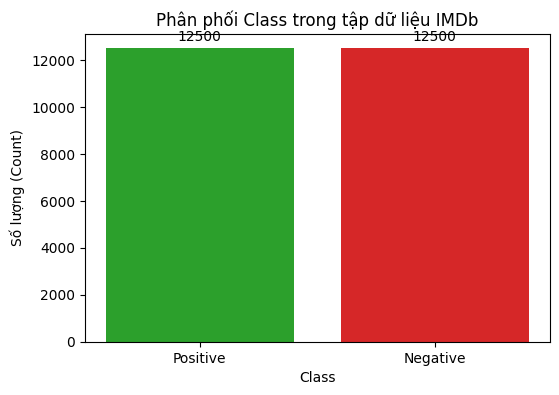

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.DataFrame({
    'text': corpus_data,
    'label': targets
})
df['class_name'] = df['label'].map({1: 'Positive', 0: 'Negative'})
num_samples = len(df)
num_classes = df['label'].nunique()
missing_text = df['text'].isnull().sum() + (df['text'].str.strip() == '').sum()
missing_labels = df['label'].isnull().sum()
duplicate_docs = df.duplicated(subset=['text']).sum()
df['doc_length'] = df['text'].apply(lambda x: len(str(x).split()))
class_counts = df['class_name'].value_counts()
class_percentages = (class_counts / num_samples) * 100
dist_df = pd.DataFrame({
    'Class': class_counts.index,
    'Count': class_counts.values,
    'Percentage': class_percentages.values.round(2).astype(str) + '%'
})
print("=== THỐNG KÊ DATASET TRƯỚC KHI TRAIN ===")
print(f"■ Số samples: {num_samples}")
print(f"■ Số classes: {num_classes}")
print(f"■ Missing text: {missing_text}")
print(f"■ Missing labels: {missing_labels}")
print(f"■ Duplicate documents: {duplicate_docs}")
print(f"■ Document length: Trung bình {df['doc_length'].mean():.1f} từ (Min: {df['doc_length'].min()}, Max: {df['doc_length'].max()})\n")

print("■ Class distribution:")
print(dist_df.to_string(index=False))
plt.figure(figsize=(6, 4))
bars = plt.bar(class_counts.index, class_counts.values, color=['#2ca02c', '#d62728'])
plt.title('Phân phối Class trong tập dữ liệu IMDb')
plt.xlabel('Class')
plt.ylabel('Số lượng (Count)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 200, int(yval), ha='center', va='bottom')

plt.show()

#12. Data leakage

In [8]:
(train_docs, train_lbls), (val_docs, val_lbls), (test_docs, test_lbls) = split_train_val_test(
    corpus_data=corpus_data,
    targets=targets,
    train_frac=0.7,
    val_frac=0.15,
    test_frac=0.15,
    seed_val=42
)

print("=== KẾT QUẢ CHIA DATASET ===")
print(f"Tập Train:      {len(train_docs)} mẫu (dùng để fit TF-IDF/Word2Vec và train model)")
print(f"Tập Validation: {len(val_docs)} mẫu (dùng để tinh chỉnh tham số)")
print(f"Tập Test:       {len(test_docs)} mẫu (giữ bí mật hoàn toàn đến phút cuối)")

=== KẾT QUẢ CHIA DATASET ===
Tập Train:      17500 mẫu (dùng để fit TF-IDF/Word2Vec và train model)
Tập Validation: 3750 mẫu (dùng để tinh chỉnh tham số)
Tập Test:       3750 mẫu (giữ bí mật hoàn toàn đến phút cuối)


### Quy trình chống Data Leakage

- **Tách dữ liệu ngay từ đầu:** Sử dụng văn bản thô trong `corpus_data` để chia thành ba tập `train_docs`, `val_docs` và `test_docs` trước khi thực hiện các bước xử lý dữ liệu.

- **Giữ riêng tập Validation và Test:** Khi huấn luyện TF-IDF hoặc xây dựng ma trận PPMI kết hợp SVD, chỉ sử dụng `train_docs` để học từ vựng và tính các trọng số cần thiết. Không sử dụng dữ liệu từ Validation hoặc Test trong quá trình này.

- **Chỉ Transform trên Validation và Test:** Sau khi hoàn tất việc huấn luyện trên tập Train, sử dụng bộ vectorizer đã được thiết lập để chuyển đổi `val_docs` và `test_docs` thông qua hàm `transform()`, không gọi lại `fit()`.

Nếu xuất hiện từ mới trong tập Test mà không có trong từ điển đã học từ Train, vectorizer sẽ không tự bổ sung từ đó. Quy trình này giúp hạn chế Data Leakage và bảo đảm việc đánh giá phản ánh đúng khả năng xử lý dữ liệu chưa từng xuất hiện trong quá trình huấn luyện.

#13. Core Implementation & 14. Experiment 2 — Baseline: TF-IDF + Logistic Regression

In [9]:
import time
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf_vectorizer = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf_vectorizer.fit_transform(train_docs)
X_test_tfidf = tfidf_vectorizer.transform(test_docs)
vocab_size = len(tfidf_vectorizer.vocabulary_)
classifier_lr = LogisticRegression(max_iter=1000)
start_time = time.time()
classifier_lr.fit(X_train_tfidf, train_lbls)
training_time = time.time() - start_time
y_pred_lr = classifier_lr.predict(X_test_tfidf)
metrics_lr = compute_classification_metrics(test_lbls, y_pred_lr)
experiment_2_results = [{
    "Model": "TF-IDF + LR",
    "Train Time (s)": round(training_time, 4),
    "Vocab Size": vocab_size,
    "Accuracy": round(metrics_lr['accuracy'], 4),
    "Precision": round(metrics_lr['precision'], 4),
    "Recall": round(metrics_lr['recall'], 4),
    "F1": round(metrics_lr['f1'], 4)
}]

df_exp2 = pd.DataFrame(experiment_2_results)
print("=== KẾT QUẢ EXPERIMENT 2 (BASELINE) ===")
print(df_exp2.to_string(index=False))

=== KẾT QUẢ EXPERIMENT 2 (BASELINE) ===
      Model  Train Time (s)  Vocab Size  Accuracy  Precision  Recall     F1
TF-IDF + LR          3.0128       10000    0.8779     0.8688  0.8875 0.8781


#15. Experiment 3 — Representation Comparison: TF-IDF vs Average Word2Vec vs Linear SVM

In [10]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

tfidf_vec = TfidfVectorizer(max_features=10000)
X_train_tfidf = tfidf_vec.fit_transform(train_docs)
X_test_tfidf = tfidf_vec.transform(test_docs)

clf_lr_tfidf = LogisticRegression(max_iter=1000, random_state=42)
clf_lr_tfidf.fit(X_train_tfidf, train_lbls)
y_pred_A = clf_lr_tfidf.predict(X_test_tfidf)
metrics_A = compute_classification_metrics(test_lbls, y_pred_A)

train_docs_tok = [tokenize(doc) for doc in train_docs]
test_docs_tok = [tokenize(doc) for doc in test_docs]

emb_dict, vec_dim = train_word_embeddings_ppmi_svd(
    docs_tokens=train_docs_tok,
    vec_size=100,
    ctx_window=3,
    max_terms=10000
)

X_train_w2v = compute_corpus_embeddings(train_docs_tok, emb_dict, vec_dim)
X_test_w2v = compute_corpus_embeddings(test_docs_tok, emb_dict, vec_dim)

clf_lr_w2v = LogisticRegression(max_iter=1000, random_state=42)
clf_lr_w2v.fit(X_train_w2v, train_lbls)
y_pred_B = clf_lr_w2v.predict(X_test_w2v)
metrics_B = compute_classification_metrics(test_lbls, y_pred_B)


clf_svm_tfidf = LinearSVC(max_iter=1000, random_state=42)
clf_svm_tfidf.fit(X_train_tfidf, train_lbls)
y_pred_C = clf_svm_tfidf.predict(X_test_tfidf)
metrics_C = compute_classification_metrics(test_lbls, y_pred_C)

results_exp3 = [
    {
        "Representation": "TF-IDF",
        "Classifier": "Logistic Regression",
        "Accuracy": round(metrics_A['accuracy'], 4),
        "Precision": round(metrics_A['precision'], 4),
        "Recall": round(metrics_A['recall'], 4),
        "F1": round(metrics_A['f1'], 4)
    },
    {
        "Representation": "Avg Word2Vec",
        "Classifier": "Logistic Regression",
        "Accuracy": round(metrics_B['accuracy'], 4),
        "Precision": round(metrics_B['precision'], 4),
        "Recall": round(metrics_B['recall'], 4),
        "F1": round(metrics_B['f1'], 4)
    },
    {
        "Representation": "TF-IDF",
        "Classifier": "Linear SVM",
        "Accuracy": round(metrics_C['accuracy'], 4),
        "Precision": round(metrics_C['precision'], 4),
        "Recall": round(metrics_C['recall'], 4),
        "F1": round(metrics_C['f1'], 4)
    }
]

df_exp3 = pd.DataFrame(results_exp3)
print("=== BẢNG SO SÁNH EXPERIMENT 3 ===")
print(df_exp3.to_string(index=False))

df_exp3.to_csv('results.csv', index=False)

=== BẢNG SO SÁNH EXPERIMENT 3 ===
Representation          Classifier  Accuracy  Precision  Recall     F1
        TF-IDF Logistic Regression    0.8779     0.8688  0.8875 0.8781
  Avg Word2Vec Logistic Regression    0.8416     0.8344  0.8488 0.8415
        TF-IDF          Linear SVM    0.8813     0.8732  0.8897 0.8814


### 1. Đánh giá phương pháp biểu diễn: TF-IDF vs. Average Word2Vec

- **Kết quả:** Với cùng thuật toán Logistic Regression, TF-IDF đạt F1-score `0.8781`, cao hơn Average Word2Vec với F1-score `0.8415`.

- **Giải thích:** TF-IDF hoạt động hiệu quả trong bài toán phân tích cảm xúc vì có thể làm nổi bật những từ mang sắc thái cảm xúc rõ rệt như `terrible` hoặc `masterpiece`, đồng thời giảm trọng số của những từ xuất hiện phổ biến. Ngược lại, Average Word2Vec lấy trung bình vector của tất cả các từ trong câu. Cách biểu diễn này có thể làm giảm ảnh hưởng của những từ mang cảm xúc mạnh khi chúng được kết hợp với nhiều từ ít có giá trị phân loại, khiến mô hình khó nhận diện chính xác sắc thái cảm xúc của câu.

### 2. Đánh giá thuật toán phân loại: Logistic Regression vs. Linear SVM

- **Kết quả:** Trên cùng dữ liệu TF-IDF, Linear SVM đạt F1-score `0.8814`, nhỉnh hơn Logistic Regression với `0.8781`. Đây là kết quả tốt nhất trong ba thử nghiệm.

- **Giải thích:** Dữ liệu TF-IDF có số chiều lớn và phần lớn giá trị bằng 0. Linear SVM phù hợp với dạng dữ liệu này vì có khả năng tìm ranh giới phân loại bằng cách tối đa hóa khoảng cách giữa hai lớp. Trong khi đó, Logistic Regression tối ưu hàm mất mát log-loss để dự đoán xác suất thuộc từng lớp. Sự khác biệt trong cách tối ưu có thể góp phần tạo ra chênh lệch hiệu suất giữa hai mô hình. Tuy nhiên, mức chênh lệch F1-score khá nhỏ nên chưa đủ để khẳng định Linear SVM luôn tốt hơn Logistic Regression.

### 3. Phân tích sự chênh lệch giữa Precision và Recall

- **Quan sát:** Ở cả ba mô hình, Recall dao động khoảng `0.84–0.88` và luôn cao hơn Precision, nằm trong khoảng `0.83–0.87`.

- **Ý nghĩa:** Nếu lớp Positive đại diện cho các đánh giá tích cực, Recall cao hơn Precision cho thấy mô hình nhận diện được phần lớn đánh giá tích cực thực sự, nhưng trong số những đánh giá được dự đoán là tích cực vẫn có một tỷ lệ dự đoán nhầm. Điều này tương ứng với việc có ít False Negatives hơn tương đối, nhưng vẫn tồn tại False Positives.

Có thể điều chỉnh ngưỡng phân loại Threshold để thay đổi sự cân bằng giữa Precision và Recall. Tuy nhiên, cần đánh giá trên tập Validation để chọn ngưỡng phù hợp, sau đó mới báo cáo kết quả trên tập Test.

#17. Experiment 4 — Word order

In [11]:
import numpy as np
s1 = "this movie is good"
s2 = "this movie is not good"
v1 = compute_corpus_embeddings([tokenize(s1)], emb_dict, vec_dim)
v2 = compute_corpus_embeddings([tokenize(s2)], emb_dict, vec_dim)
cos_sim = float(np.dot(v1[0], v2[0]) / (np.linalg.norm(v1[0]) * np.linalg.norm(v2[0])))
p1_w2v = clf_lr_w2v.predict(v1)[0]
p2_w2v = clf_lr_w2v.predict(v2)[0]
prob1_w2v = clf_lr_w2v.predict_proba(v1)[0][1]
prob2_w2v = clf_lr_w2v.predict_proba(v2)[0][1]
t1_tf = tfidf_vec.transform([s1])
t2_tf = tfidf_vec.transform([s2])
p1_tf = clf_lr_tfidf.predict(t1_tf)[0]
p2_tf = clf_lr_tfidf.predict(t2_tf)[0]
prob1_tf = clf_lr_tfidf.predict_proba(t1_tf)[0][1]
prob2_tf = clf_lr_tfidf.predict_proba(t2_tf)[0][1]
print("=== THỰC NGHIỆM 4: WORD ORDER & NEGATION ===")
print("-" * 85)
print(f"S1: '{s1}'")
print(f"S2: '{s2}'")
print(f"Cosine similarity giữa S1 và S2 (Word2Vec space): {cos_sim:.4f}")
print("-" * 85)
print(f"{'Model':<25} | {'S1 Prediction (prob)':<25} | {'S2 Prediction (prob)':<25}")
print("-" * 85)
print(f"{'Avg Word2Vec + LR':<25} | {f'Class {p1_w2v} ({prob1_w2v:.4f})':<25} | {f'Class {p2_w2v} ({prob2_w2v:.4f})':<25}")
print(f"{'TF-IDF (Unigram) + LR':<25} | {f'Class {p1_tf} ({prob1_tf:.4f})':<25} | {f'Class {p2_tf} ({prob2_tf:.4f})':<25}")
print("-" * 85)

=== THỰC NGHIỆM 4: WORD ORDER & NEGATION ===
-------------------------------------------------------------------------------------
S1: 'this movie is good'
S2: 'this movie is not good'
Cosine similarity giữa S1 và S2 (Word2Vec space): 0.9901
-------------------------------------------------------------------------------------
Model                     | S1 Prediction (prob)      | S2 Prediction (prob)     
-------------------------------------------------------------------------------------
Avg Word2Vec + LR         | Class 0 (0.4442)          | Class 1 (0.5128)         
TF-IDF (Unigram) + LR     | Class 1 (0.7931)          | Class 1 (0.5456)         
-------------------------------------------------------------------------------------


### 1. Phân tích sự hạn chế của Average Word2Vec qua Cosine Similarity

Mô hình Word2Vec cho điểm tương đồng giữa hai câu lên tới `0.9901`, tương đương 99,01%.

Với phương pháp Average Word2Vec, vector câu được tính bằng trung bình vector của các từ trong câu. Vì vậy, hai câu có nhiều từ chung sẽ có vector đại diện khá giống nhau, ngay cả khi ý nghĩa khác biệt.

Với câu S2, vector được tính như sau:

$$
\text{Vector}(S2) =
\frac{
v_{\text{this}} + v_{\text{movie}} + v_{\text{is}} + v_{\text{not}} + v_{\text{good}}
}{5}
$$

Bốn từ chung giữa hai câu là `this`, `movie`, `is` và `good`. Những từ này đóng góp phần lớn vào vector trung bình, khiến ảnh hưởng của từ `not` không đủ để tạo ra sự khác biệt rõ rệt. Do đó, mô hình vẫn đánh giá hai câu có độ tương đồng rất cao dù chúng mang ý nghĩa trái ngược nhau.

### 2. Hạn chế của TF-IDF với Unigram

- **Kết quả:** Với câu S1, mô hình dự đoán Tích cực với xác suất `0.7931`. Khi thêm từ `not` để tạo thành câu S2, mô hình vẫn dự đoán Tích cực nhưng xác suất giảm xuống `0.5456`.

- **Giải thích:** TF-IDF với Unigram biểu diễn mỗi từ như một đặc trưng riêng biệt, không thể hiện trực tiếp mối quan hệ giữa `not` và `good`. Logistic Regression tính điểm dựa trên trọng số của từng từ, nên từ `good` có thể đóng góp điểm tích cực lớn hơn mức điểm tiêu cực mà `not` tạo ra. Vì vậy, xác suất dự đoán giảm nhưng chưa đủ để chuyển sang lớp Tiêu cực.

Kết quả cho thấy mô hình chưa xử lý tốt cấu trúc phủ định `not good` vì chỉ xét từng từ riêng lẻ.

### 3. Hạn chế của Average Word2Vec

- **Kết quả:** Mô hình dự đoán sai câu S1 thành Tiêu cực với xác suất Tích cực `0.4442`. Khi thêm từ `not` vào S2, mô hình lại dự đoán Tích cực với xác suất `0.5128`.

- **Giải thích:** Việc lấy trung bình các vector từ làm mất thông tin về thứ tự từ và cấu trúc câu. Với câu ngắn, chỉ một từ thay đổi cũng có thể làm vector đại diện dịch chuyển theo hướng khó dự đoán. Kết quả xác suất của hai câu đều gần ngưỡng `0.5`, cho thấy mô hình chưa phân biệt rõ sắc thái cảm xúc trong ví dụ này.

Tuy nhiên, chỉ từ hai kết quả trên chưa thể kết luận mô hình đang dự đoán ngẫu nhiên. Cần đánh giá thêm trên nhiều câu để xác định mức độ ổn định của phương pháp.

### 4. Hướng khắc phục

- **Với TF-IDF:** Sử dụng N-gram thay vì chỉ dùng Unigram. Khi thêm Bigram, cụm `not good` có thể được xem là một đặc trưng riêng, giúp mô hình học được trọng số phù hợp với sắc thái phủ định.

- **Với Word Embeddings:** Thay Average Word2Vec bằng các mô hình có khả năng xử lý thứ tự và quan hệ giữa các từ, chẳng hạn RNN, LSTM hoặc Transformer. Những mô hình này có thể học cách từ `not` ảnh hưởng đến ý nghĩa của `good` dựa trên ngữ cảnh.

Nhìn chung, TF-IDF với Unigram và Average Word2Vec đều có hạn chế khi xử lý câu phủ định. Việc bổ sung đặc trưng N-gram hoặc sử dụng mô hình có khả năng nắm bắt ngữ cảnh sẽ giúp cải thiện khả năng phân biệt cảm xúc trong những trường hợp này.

#18. Experiment 5 — n-gram features

In [12]:
import time
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=5)
X_train_uni = tfidf_uni.fit_transform(train_docs)
X_test_uni = tfidf_uni.transform(test_docs)
vocab_uni = len(tfidf_uni.vocabulary_)
clf_uni = LogisticRegression(max_iter=1000, random_state=42)
start_time = time.time()
clf_uni.fit(X_train_uni, train_lbls)
time_uni = time.time() - start_time

pred_uni = clf_uni.predict(X_test_uni)
metrics_uni = compute_classification_metrics(test_lbls, pred_uni)

tfidf_bi = TfidfVectorizer(ngram_range=(1, 2), min_df=5)
X_train_bi = tfidf_bi.fit_transform(train_docs)
X_test_bi = tfidf_bi.transform(test_docs)
vocab_bi = len(tfidf_bi.vocabulary_)

clf_bi = LogisticRegression(max_iter=1000, random_state=42)

start_time = time.time()
clf_bi.fit(X_train_bi, train_lbls)
time_bi = time.time() - start_time

pred_bi = clf_bi.predict(X_test_bi)
metrics_bi = compute_classification_metrics(test_lbls, pred_bi)

results_exp5 = [
    {
        "Features": "Unigram",
        "Vocabulary": vocab_uni,
        "F1": round(metrics_uni['f1'], 4),
        "Training time": f"{time_uni:.4f} s"
    },
    {
        "Features": "Uni + Bigram",
        "Vocabulary": vocab_bi,
        "F1": round(metrics_bi['f1'], 4),
        "Training time": f"{time_bi:.4f} s"
    }
]

df_exp5 = pd.DataFrame(results_exp5)
print("=== BẢNG SO SÁNH EXPERIMENT 5 ===")
print(df_exp5.to_string(index=False))

=== BẢNG SO SÁNH EXPERIMENT 5 ===
    Features  Vocabulary     F1 Training time
     Unigram       22864 0.8817      0.6292 s
Uni + Bigram      116368 0.8850      1.1560 s


## 1. Vì sao Bigram giúp cải thiện kết quả phân loại?

Unigram chỉ xem xét từng từ riêng lẻ, nên khó nắm bắt được ý nghĩa của các từ khi chúng xuất hiện cùng nhau. Bigram khắc phục hạn chế này bằng cách ghép hai từ liên tiếp thành một đặc trưng, giúp mô hình nhận biết trật tự từ và ngữ cảnh trong câu.

Ví dụ, cụm từ *not good* mang ý nghĩa tiêu cực, khác với từ *good* khi đứng riêng lẻ. Nhờ đó, mô hình có thêm thông tin để phân biệt các câu mang ý nghĩa khác nhau.

Kết quả thực nghiệm cho thấy F1 Score tăng từ **0.8817 lên 0.8850** khi bổ sung Bigram. Mức cải thiện không lớn, nhưng cho thấy các cặp từ liên tiếp cung cấp thêm thông tin hữu ích cho quá trình phân loại.

## 2. Vì sao Bigram làm tăng số lượng đặc trưng?

Unigram xem mỗi từ là một đặc trưng riêng, trong khi Bigram bổ sung các cặp từ liên tiếp vào từ vựng. Chẳng hạn, từ *movie* có thể xuất hiện trong nhiều cụm từ như *good movie*, *bad movie* hay *this movie*. Mỗi cụm từ có thể trở thành một đặc trưng mới trong ma trận TF-IDF.

Kết quả thực nghiệm cho thấy:

- **Số lượng đặc trưng:** Tăng từ 22.864 lên 116.368, gấp khoảng 5.09 lần.
- **Thời gian huấn luyện:** Tăng từ 0.6292 giây lên 1.1560 giây, khoảng 1.84 lần.

Số lượng đặc trưng lớn hơn khiến Logistic Regression phải xử lý nhiều hệ số hơn trong quá trình huấn luyện. Vì vậy, thời gian tính toán tăng lên, trong khi F1 Score chỉ cải thiện một mức nhỏ.

## 3. Bảng so sánh kết quả

| Phương pháp | Số lượng đặc trưng | F1 Score | Thời gian huấn luyện |
|---|---:|---:|---:|
| Unigram | 22.864 | 0.8817 | 0.6292 s |
| Unigram + Bigram | 116.368 | 0.8850 | 1.1560 s |

## 4. Kết luận

Bổ sung Bigram giúp F1 Score tăng từ 0.8817 lên 0.8850, nhưng số lượng đặc trưng tăng hơn 5 lần và thời gian huấn luyện tăng gần gấp đôi. Như vậy, Bigram có cải thiện kết quả phân loại, nhưng mức tăng chưa thực sự đáng kể so với chi phí tính toán bổ sung.

#19. Evaluation

In [14]:
conf_matrix = compute_confusion_matrix(test_lbls, y_pred_A)

TP = conf_matrix[0, 0]
FN = conf_matrix[0, 1]
FP = conf_matrix[1, 0]
TN = conf_matrix[1, 1]

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print("=== CHI TIẾT ĐÁNH GIÁ MODEL A (TF-IDF + LOGISTIC REGRESSION) ===")
print("1. Các giá trị Confusion Matrix:")
print(f"   - True Positives (TP)  = {TP} (Dự đoán Tích cực đúng)")
print(f"   - True Negatives (TN)  = {TN} (Dự đoán Tiêu cực đúng)")
print(f"   - False Positives (FP) = {FP} (Dự đoán nhầm thành Tích cực)")
print(f"   - False Negatives (FN) = {FN} (Dự đoán nhầm thành Tiêu cực)")
print("-" * 60)
print("2. Kết quả Metrics:")
print(f"   - Accuracy  = {accuracy:.4f}")
print(f"   - Precision = {precision:.4f}")
print(f"   - Recall    = {recall:.4f}")
print(f"   - F1 Score  = {f1_score:.4f}")

=== CHI TIẾT ĐÁNH GIÁ MODEL A (TF-IDF + LOGISTIC REGRESSION) ===
1. Các giá trị Confusion Matrix:
   - True Positives (TP)  = 1649 (Dự đoán Tích cực đúng)
   - True Negatives (TN)  = 1643 (Dự đoán Tiêu cực đúng)
   - False Positives (FP) = 249 (Dự đoán nhầm thành Tích cực)
   - False Negatives (FN) = 209 (Dự đoán nhầm thành Tiêu cực)
------------------------------------------------------------
2. Kết quả Metrics:
   - Accuracy  = 0.8779
   - Precision = 0.8688
   - Recall    = 0.8875
   - F1 Score  = 0.8781


#20. Confusion matrix

Saved file: confusion_matrix.png


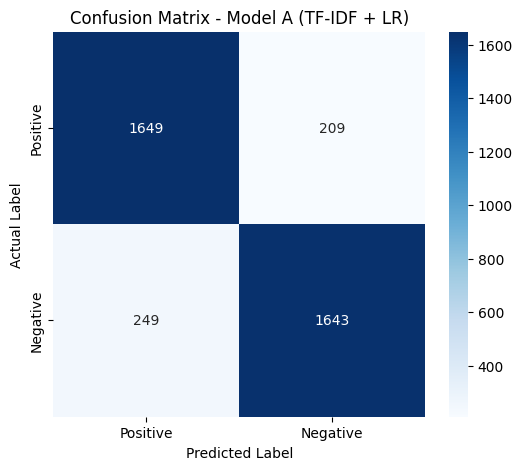

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues',
            xticklabels=['Positive', 'Negative'],
            yticklabels=['Positive', 'Negative'])

plt.title('Confusion Matrix - Model A (TF-IDF + LR)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
print("Saved file: confusion_matrix.png")

plt.show()

#21. Error analysis

In [16]:
import numpy as np
import random

correct_indices = np.where(np.array(test_lbls) == y_pred_A)[0]
incorrect_indices = np.where(np.array(test_lbls) != y_pred_A)[0]

random.seed(42)
sampled_correct = random.sample(list(correct_indices), 3)
sampled_incorrect = random.sample(list(incorrect_indices), 3)

def print_samples(indices, title):
    print(f"=== {title} ===")
    for idx in indices:
        text = test_docs[idx]
        short_text = text[:300] + "..." if len(text) > 300 else text
        true_lbl = "Positive" if test_lbls[idx] == 1 else "Negative"
        pred_lbl = "Positive" if y_pred_A[idx] == 1 else "Negative"
        print(f"Text: {short_text}")
        print(f"True: {true_lbl} | Predicted: {pred_lbl}")
        print("-" * 75)

print_samples(sampled_correct, "3 CORRECTLY CLASSIFIED EXAMPLES")
print("\n")
print_samples(sampled_incorrect, "3 INCORRECTLY CLASSIFIED EXAMPLES")

=== 3 CORRECTLY CLASSIFIED EXAMPLES ===
Text: Thankfully saw this on a plane to Singapore recently (thought I'd missed it at the Cinemalaya filmfest). Paris, je t'aime is a collection of 20 short films (about 5 mins each) by 20 directors showing love in various pockets of contemporary Paris.<br /><br />One of my fave segments is 'Parc Monceau' ...
True: Positive | Predicted: Positive
---------------------------------------------------------------------------
Text: The title sequence shows the credits written on a rain-soaked sidewalk as people trod on it; music is provided by someone whistling Alfred Newman's "Street Scene." Then we meet Det. Sgt. Mark Dixon (Dana Andrews), who always wanted to be something his old man wasn't: a guy on the right side of the l...
True: Positive | Predicted: Positive
---------------------------------------------------------------------------
Text: Errol Flynn's greatest movie, not just a sports movie with a wonder last 5 minutes where Ward Bond shines. D

| **Text ** | **True** | **Predicted** | **Analysis** |
| :--- | :---: | :---: | :--- |
| *"...Paris, je t'aime is a collection... One of my fave segments..."* | Positive | Positive | Mô hình dự đoán đúng nhờ nhận diện các từ mang sắc thái tích cực như "fave" và "love". |
| *"...Dana Andrews, who always wanted to be something his old man wasn't..."* | Positive | Positive | Đoạn văn chủ yếu mô tả cốt truyện, không có nhiều từ tiêu cực rõ ràng. Các từ tích cực xuất hiện ở phần sau giúp mô hình dự đoán đúng nhãn Positive. |
| *"Errol Flynn's greatest movie... wonder last 5 minutes where Ward Bond shines... classic..."* | Positive | Positive | Các từ như "greatest", "shines" và "classic" mang sắc thái tích cực rõ ràng, giúp mô hình đưa ra dự đoán chính xác. |
| *"This is a truly awful "B" movie... excuse to push the war effort and highlight some popular music groups..."* | Negative | Positive | **Hạn chế của Bag-of-Words:** Các từ tiêu cực như "awful" và "witless" xuất hiện cùng những từ trung tính ở phần sau. Do mô hình không xét đến ngữ cảnh và mối liên hệ giữa các từ, những đặc trưng này có thể khiến tổng điểm nghiêng về Positive. |
| *"This reboot is like a processed McDonald's meal compared to Ang Lee's very good but very underrated 2003..."* | Negative | Positive | **Nhầm lẫn trong câu so sánh:** Người viết chê bộ phim hiện tại bằng cách so sánh với một bộ phim cũ được đánh giá tốt. Mô hình nhận diện các từ tích cực như "very good" và "underrated" nhưng không xác định được chúng dùng để nói về bộ phim nào, dẫn đến dự đoán sai. |
| *"THE BRAIN THAT WOULDN'T DIE was considered so distasteful... the thing is both lurid and lewd..."* | Positive | Negative | **Sắc thái từ ngữ phụ thuộc vào ngữ cảnh:** Trong một số bài review phim cult, những từ như "distasteful", "lurid" và "lewd" có thể được dùng để mô tả các đặc điểm hấp dẫn của bộ phim đối với người hâm mộ thể loại này. Tuy nhiên, mô hình dựa trên TF-IDF thường xem đây là những từ tiêu cực, khiến dự đoán không khớp với nhãn thực tế. |

#22. Inspect model weights

In [17]:
import numpy as np
import pandas as pd

feature_names = tfidf_vec.get_feature_names_out()


weights = clf_lr_tfidf.coef_[0]

df_weights = pd.DataFrame({
    'Feature': feature_names,
    'Weight': weights
})

df_weights_sorted = df_weights.sort_values(by='Weight', ascending=False)

top_positive = df_weights_sorted.head(15)
top_negative = df_weights_sorted.tail(15).sort_values(by='Weight', ascending=True)

print("=== TOP POSITIVE FEATURES (w >> 0) ===")
print(top_positive.to_string(index=False))

print("\n=== TOP NEGATIVE FEATURES (w << 0) ===")
print(top_negative.to_string(index=False))

=== TOP POSITIVE FEATURES (w >> 0) ===
  Feature   Weight
    great 6.288333
excellent 5.575928
     best 4.635887
  perfect 4.170211
wonderful 3.845152
  amazing 3.624354
     well 3.572210
    loved 3.261660
      fun 3.166589
brilliant 3.134838
 favorite 3.047118
    today 2.978764
  enjoyed 2.935380
     also 2.856909
      and 2.854464

=== TOP NEGATIVE FEATURES (w << 0) ===
      Feature    Weight
        worst -8.250252
          bad -7.110607
        awful -5.624903
       boring -5.611234
        waste -5.530335
         poor -4.627211
     terrible -4.308624
      nothing -4.271929
         dull -4.213840
        worse -4.022675
           no -3.908932
unfortunately -3.707139
     horrible -3.532532
     annoying -3.406075
       stupid -3.397504


### Trả lời: Các feature này có thực sự ý nghĩa đối với bài toán không?

Thông qua việc phân tích trọng số, ta có thể thấy Logistic Regression đã học được nhiều đặc trưng ngôn ngữ liên quan đến cảm xúc trong bài toán Sentiment Analysis. Tuy nhiên, không phải feature nào có trọng số cao cũng thực sự phản ánh cảm xúc.

**1. Mô hình học được các từ thể hiện cảm xúc**

- **Top Negative:** Các từ như `worst` (-8.25), `bad` (-7.11), `awful`, `boring` và `waste` đều mang sắc thái tiêu cực rõ rệt. Trọng số âm lớn cho thấy sự xuất hiện của những từ này làm tăng xu hướng dự đoán nhãn Negative.
- **Top Positive:** Các từ như `great` (6.28), `excellent` (5.57), `best`, `perfect` và `brilliant` thường được dùng để khen ngợi. Trọng số dương cho thấy chúng góp phần đẩy dự đoán về phía Positive.

Những kết quả này phù hợp với ý nghĩa thông thường của các từ và cho thấy mô hình đã học được những tín hiệu cảm xúc hữu ích từ dữ liệu huấn luyện.

**2. Phát hiện những đặc trưng chưa thực sự có ý nghĩa**

Phân tích trọng số còn giúp phát hiện những đặc trưng khó giải thích chỉ bằng các chỉ số như Accuracy hay F1 Score.

- **Các từ ít thể hiện cảm xúc:** Trong danh sách Top Positive, những từ như `also` (2.85), `and` (2.85) hay `today` (2.97) lại có trọng số dương tương đối cao.
- **Nguyên nhân:** Logistic Regression học trọng số dựa trên mối tương quan thống kê giữa các từ và nhãn trong tập huấn luyện. Nếu một từ xuất hiện thường xuyên hơn trong các bài review Positive, mô hình có thể gán cho nó trọng số dương, ngay cả khi bản thân từ đó không thể hiện cảm xúc.
- **Ý nghĩa:** Những đặc trưng này có thể phản ánh cách viết hoặc sự phân bố của dữ liệu thay vì nội dung cảm xúc. Đây cũng là lý do cần xem xét lại bước tiền xử lý, đặc biệt là việc loại bỏ stopwords. Tuy nhiên, không nên xóa từ một cách máy móc vì một số từ tưởng như ít ý nghĩa vẫn có thể hữu ích trong những ngữ cảnh nhất định.

**Kết luận**

Phân tích trọng số là một bước quan trọng trong Model Interpretability, giúp giải thích cách Logistic Regression đưa ra dự đoán. Các từ mang sắc thái cảm xúc rõ ràng cho thấy mô hình đã học được những đặc trưng phù hợp, trong khi các từ như `also`, `and` hay `today` gợi ý rằng mô hình có thể đang tận dụng cả những tương quan thống kê chưa thực sự có ý nghĩa.

Từ đó, ta có thể xác định hướng cải thiện bước tiền xử lý và đánh giá lại mô hình bằng thực nghiệm, thay vì chỉ dựa vào Accuracy hoặc F1 Score.

#23. Application

In [18]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
train_texts = [
    "this movie is fantastic and great",
    "i love this film so much, absolute masterpiece",
    "terrible waste of time, awful acting",
    "boring plot and a really bad experience",
    "brilliant storytelling and wonderful actors",
    "horrible movie, i hate it completely"
]
train_labels = [1, 1, 0, 0, 1, 0] # 1: Positive, 0: Negative

vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(train_texts)

model = LogisticRegression()
model.fit(X_train, train_labels)

def predict_sentiment(text, model=model, vectorizer=vectorizer):
    vec = vectorizer.transform([text])
    prob = model.predict_proba(vec)[0]
    pred_label = model.predict(vec)[0]

    sentiment = "Positive" if pred_label == 1 else "Negative"
    confidence = prob[pred_label]

    return sentiment, confidence, prob[1]
sample_reviews = [
    "An absolute masterpiece with amazing acting.",
    "The plot was completely boring and terrible.",
    "This was a fun and wonderful movie.",
    "A total waste of time, I hated it."
]

print("=== APPLICATION — REAL-TIME SENTIMENT PREDICTION ===")
print("-" * 65)
for r in sample_reviews:
    sent, conf, pos_p = predict_sentiment(r)
    print(f"Review: '{r}'")
    print(f"-> Sentiment: {sent:<10} | Confidence: {conf * 100:.2f}% | P(Positive) = {pos_p:.4f}\n")
print("-" * 65)

=== APPLICATION — REAL-TIME SENTIMENT PREDICTION ===
-----------------------------------------------------------------
Review: 'An absolute masterpiece with amazing acting.'
-> Sentiment: Positive   | Confidence: 51.37% | P(Positive) = 0.5137

Review: 'The plot was completely boring and terrible.'
-> Sentiment: Negative   | Confidence: 57.80% | P(Positive) = 0.4220

Review: 'This was a fun and wonderful movie.'
-> Sentiment: Positive   | Confidence: 56.89% | P(Positive) = 0.5689

Review: 'A total waste of time, I hated it.'
-> Sentiment: Negative   | Confidence: 59.05% | P(Positive) = 0.4095

-----------------------------------------------------------------


#25. Individual learning check

### **Câu hỏi:**

> **TF-IDF khác Average Word2Vec ở điểm nào?**

### **Trả lời chi tiết:**

Sự khác biệt chính giữa hai phương pháp nằm ở cách biểu diễn văn bản và loại thông tin mà chúng có thể nắm bắt.

**1. Không gian đặc trưng**

- **TF-IDF:** Biểu diễn văn bản bằng vector thưa, có số chiều bằng kích thước từ vựng. Nếu từ vựng có 100.000 từ, mỗi văn bản có thể được biểu diễn bằng vector 100.000 chiều. Mỗi chiều tương ứng với một từ, có giá trị phản ánh mức độ quan trọng của từ đó trong văn bản.
- **Average Word2Vec:** Biểu diễn văn bản bằng vector dày, có số chiều cố định, thường là 100–300 chiều tùy mô hình. Mỗi từ được chuyển thành một vector nhúng, sau đó lấy trung bình các vector này để tạo ra vector đại diện cho cả câu.

**2. Cách tạo vector văn bản**

- **TF-IDF:** Tính trọng số cho từng từ dựa trên tần suất xuất hiện trong văn bản và mức độ phổ biến của từ trong toàn bộ tập dữ liệu.
- **Average Word2Vec:** Lấy trung bình cộng các vector Word2Vec của những từ có trong câu. Cách này giúp thu gọn biểu diễn, nhưng có thể làm mất thông tin về thứ tự từ và cấu trúc câu.

**3. Khả năng nắm bắt ngữ nghĩa**

- **TF-IDF:** Xem mỗi từ là một đặc trưng độc lập. Chẳng hạn, `good` và `great` tương ứng với hai chiều khác nhau, không thể hiện trực tiếp mối quan hệ ngữ nghĩa giữa chúng.
- **Average Word2Vec:** Các từ có ngữ cảnh sử dụng tương tự nhau thường có vector gần nhau trong không gian nhúng. Vì vậy, mô hình có thể tận dụng sự tương đồng ngữ nghĩa giữa các từ, ngay cả khi chúng không trùng khớp hoàn toàn.

### **Kết luận**

TF-IDF phù hợp khi cần biểu diễn rõ ràng tầm quan trọng của từng từ, trong khi Average Word2Vec tạo ra biểu diễn gọn hơn và có khả năng thể hiện sự tương đồng ngữ nghĩa. Tuy nhiên, việc lấy trung bình vector có thể làm mất thông tin về thứ tự từ và các cấu trúc quan trọng như phủ định. Vì vậy, phương pháp tốt hơn còn phụ thuộc vào dữ liệu và bài toán cụ thể.

#